In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('../../src/zero_to_hero/part_02_makemore/names.txt', 'r').read().splitlines()

In [3]:
len(words)

32033

In [7]:
# We had S/E special tokens, but now just "."
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [8]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22767, 3]) torch.Size([22767])
torch.Size([22799, 3]) torch.Size([22799])


In [55]:
import numpy as np
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

# Why does he not apply Kaiming to W2?
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 5/3 / np.sqrt(n_embd * block_size) # tanh saturation step, Kaiming
b1 = torch.randn(n_hidden,                        generator=g) * 0.01 # tanh saturation step, helps to break symmetry
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 5/3 / np.sqrt(n_hidden) # Initialise step 1
b2 = torch.randn(vocab_size,                      generator=g) * 0.0 # initialise step 2

# BatchNorm parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

#parameters = [C, W1, W2, b2, bngain, bnbias]
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [56]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())


      0/ 200000: 4.0964
  10000/ 200000: 2.4429
  20000/ 200000: 2.3538
  30000/ 200000: 2.0238
  40000/ 200000: 1.9630
  50000/ 200000: 2.3640
  60000/ 200000: 2.2012
  70000/ 200000: 2.0850
  80000/ 200000: 2.0044
  90000/ 200000: 2.0481
 100000/ 200000: 2.4591
 110000/ 200000: 2.1773
 120000/ 200000: 2.0645
 130000/ 200000: 2.3021
 140000/ 200000: 2.2061
 150000/ 200000: 2.1787
 160000/ 200000: 2.0458
 170000/ 200000: 2.0123
 180000/ 200000: 2.3763
 190000/ 200000: 1.9348


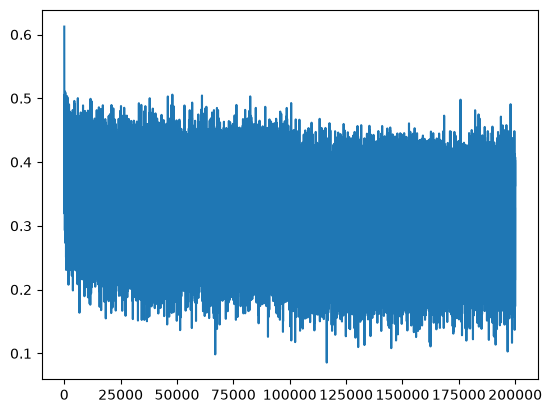

In [57]:
plt.plot(lossi)

In [58]:
# this decorator disables gradient tracking - if we won't ever call loss.backward, more efficient
@torch.no_grad() 
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1  + b1
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0377089977264404
val 2.1023800373077393


In [19]:
# Configuring initial loss - look at initialisation
# For us should be around log(27) (equal weighted model) (-log(1/27) is nll)
# Can use some initialisation technique (Glorot, He)

In [24]:
# we initialise b2 to 0, W2 by 0.01
# Don't do 0! We'll see why
# Loss (2.11/2.16) -> (2.06/2.13)

(array([2295.,  143.,   84.,   87.,   54.,   84.,   37.,   30.,   27.,
          39.,   19.,   23.,   19.,   16.,   12.,   30.,   24.,    9.,
          23.,    9.,   17.,   22.,   16.,   16.,   20.,   26.,   10.,
          12.,   12.,   20.,   14.,   18.,   11.,   18.,   13.,   28.,
          29.,   23.,   22.,   20.,   26.,   25.,   40.,   33.,   66.,
          62.,   78.,   78.,  161., 2400.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

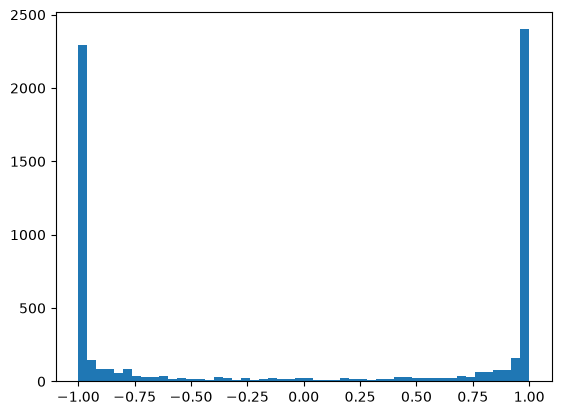

In [37]:
# Next... if we look at h (not hpreact), we get a lot of ones - saturated!
# This gives us really small gradients (gradient of tanh is (1 - t ** 2))
# h massively saturated, as hpreact very large
a1 = h.view(-1).tolist()
plt.hist(a1, 50)

(array([  8.,  11.,  19.,  48.,  48.,  65.,  93., 112.,  88., 103., 123.,
        141., 140., 151., 151., 158., 160., 164., 175., 192., 182., 186.,
        155., 171., 170., 189., 231., 189., 202., 171., 184., 169., 176.,
        192., 140., 166., 164., 164., 179., 133., 130.,  95., 126., 108.,
         88.,  66.,  36.,  43.,  29.,  16.]),
 array([-0.95887482, -0.92055975, -0.88224467, -0.8439296 , -0.80561452,
        -0.76729945, -0.72898438, -0.6906693 , -0.65235423, -0.61403915,
        -0.57572408, -0.537409  , -0.49909393, -0.46077885, -0.42246378,
        -0.38414871, -0.34583363, -0.30751856, -0.26920348, -0.23088841,
        -0.19257333, -0.15425826, -0.11594318, -0.07762811, -0.03931304,
        -0.00099796,  0.03731711,  0.07563219,  0.11394726,  0.15226234,
         0.19057741,  0.22889249,  0.26720756,  0.30552263,  0.34383771,
         0.38215278,  0.42046786,  0.45878293,  0.49709801,  0.53541308,
         0.57372816,  0.61204323,  0.6503583 ,  0.68867338,  0.72698845,
 

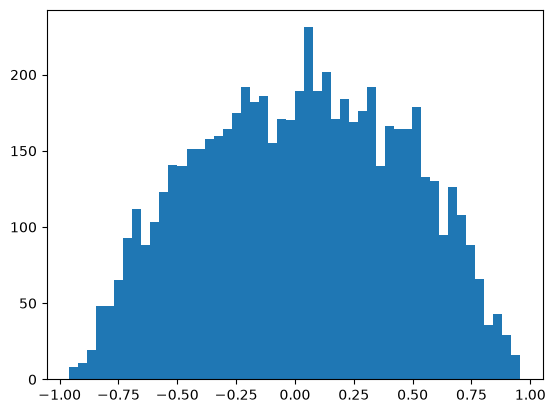

In [40]:
# post saturation fix
a1 = h.view(-1).tolist()
plt.hist(a1, 50)

(array([  1.,   1.,   0.,   1.,   2.,   5.,   5.,   5.,  12.,  16.,  29.,
         33.,  48.,  67.,  90.,  85., 132., 194., 261., 271., 279., 325.,
        310., 396., 460., 403., 482., 330., 330., 263., 302., 278., 201.,
        202., 139., 120.,  74.,  84.,  43.,  37.,  19.,  17.,  18.,   9.,
         15.,   1.,   2.,   1.,   1.,   1.]),
 array([-25.43098831, -24.426096  , -23.42120369, -22.41631138,
        -21.41141907, -20.40652676, -19.40163445, -18.39674213,
        -17.39184982, -16.38695751, -15.3820652 , -14.37717289,
        -13.37228058, -12.36738827, -11.36249596, -10.35760365,
         -9.35271133,  -8.34781902,  -7.34292671,  -6.3380344 ,
         -5.33314209,  -4.32824978,  -3.32335747,  -2.31846516,
         -1.31357285,  -0.30868053,   0.69621178,   1.70110409,
          2.7059964 ,   3.71088871,   4.71578102,   5.72067333,
          6.72556564,   7.73045795,   8.73535027,   9.74024258,
         10.74513489,  11.7500272 ,  12.75491951,  13.75981182,
         14.764704

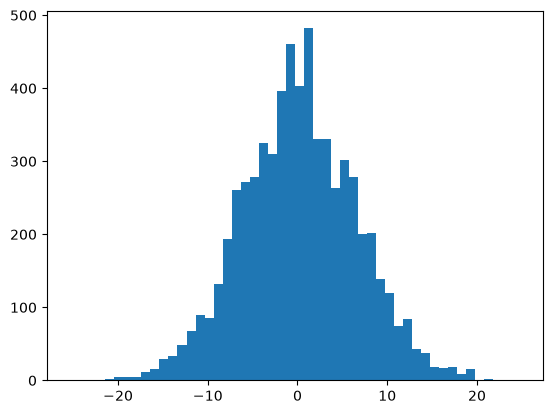

In [29]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [36]:
# However we see that no neuron has all examples giving saturated tanh (___dead neuron___)
# So some gradients will flow through
# How do dead neurons happen? What about with high learning rate?

In [47]:
# We scale W1, b1 by 0.2, 0.01
# Loss (2.06/2.13) -> (2.03/2.10)

In [46]:
# In deeper problems, these are _must fix_ and can blow up if not fixed
# Here, we just needed to train more

## Magic numbers

In [48]:
# Next, we deal with initialisation magic numbers

In [52]:
# We want to preserve variance across layers, leading us to normal Glorot or Kaiming initialisation
# Divide by square root of fan in (He) Note with Tanh we would lose the factor of 2 that He keeps for ReLU (this is gain for nonlinearity in pytorch)
# Delving deep into rectifiers - paper that has this
# Karpathy suggests Kaiming is common
# Gain is for "contracting" functions in some way - scale up to get past contracting and preserve variance

In [53]:
# Things like residual connections, batch normalisation etc, and Adam make it less crucial to initialise
# Kaiming and done is fine

In [59]:
# Loss (2.03/2.10) -> (2.03/2.10)

## Batch Normalization

In [60]:
# Core idea, just force hpreact and normalise to be standard gaussian
# This is differentiable, so okay

In [62]:
# We don't want it to be always unit gaussian, want it shifted around
# So we take unit_gaussian -> c1*unit_gaussian + c2 for some constants
# These are learned - start again at 47:00 (c1 =1, c2 =0 at the start)

In [2]:
# Shouldn't really expect an improvement - our initialisation did it
# This helps for more complicated neural nets
# Note that logit for an example is now a function of what is in the batch
# mean/std slightly unstable - acts as a regulariser

In [3]:
# Question - how do we predict from a single example?
# The NN expects batches, so what is bnean?
# At the end of training, measure mean/std over the entire training set to get bnmean and bnstd, use these

In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  hpreact = bngain * (hpreact - hpreact.mean(axis=0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
